### Segundo parcial inferencia estadística y reconocimiento de patrones. 

### ALUMNAS : Parallela Luciana Sol y Gonzalez Camila Belen. 

### Algoritmo: DBSCAN. 

In [1]:
#Librerias kmeans, dbscan y clustering jerarquico 
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder 
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances_argmin_min
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram 
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score 
from collections import Counter


### Cargamos los datos 

In [2]:
datos = pd.read_csv('/Users/Camila/Desktop/Segundo Parcial /X_exportado.csv')

#### Realizamos un analisis exploratorio para ver:
1. Nombres de las columnas
2. Cuantas filas tenemos y el total de datos
3. Cuantos valores nulos tenemos
4. Si hay datos duplicados

In [4]:
datos.columns

Index(['0', '1'], dtype='object')

In [ ]:
datos.shape 

(750, 2)

In [ ]:
datos.isna().sum() #Vemos que no hay datos faltantes
datos.duplicated().sum() #No hay datos duplicados

np.int64(0)

### Preprocesamiento de datos: estandarizamos las variables

In [3]:
scaler = StandardScaler()
datos_scaled = scaler.fit_transform(datos)

datos_scaled_df = pd.DataFrame(            # Convertimos el array escalado a un DataFrame de pandas para luego agregar la columna de clusters
    datos_scaled,
    columns=datos.columns,
    index=datos.index
)

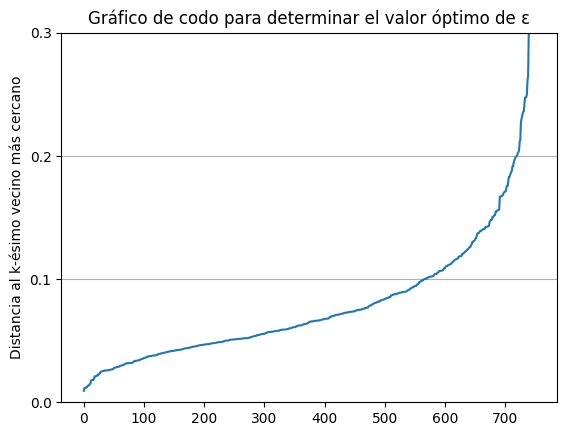

In [ ]:
neighbors = NearestNeighbors(n_neighbors=3)  #Elegimos k-neighbors = 3
neighbors_fit = neighbors.fit(datos_scaled)

distances, indices = neighbors_fit.kneighbors(datos_scaled) 

distances = np.sort(distances, axis=0)
distances = distances[:,-1] 

# plot distances
plt.yticks(np.arange(0, 2.1, 0.1))
plt.ylim(0, 0.3)
plt.title('Gráfico de codo para determinar el valor óptimo de ε')
plt.ylabel('Distancia al k-ésimo vecino más cercano')
plt.grid(True, axis='y')
plt.plot(distances)

### Basandonos en el método del codo podríamos quedarnos con epsilon = 0.1, pero ahora vamos a evaluar a partir de distintos valores de epsilon el desempeño del algoritmo a través de métricas, de modo de quedarnos con el mejor valor a partir de resultados factibles 

In [4]:
epsilon_siluetas = []
epsilon_davies_bouldin_indice = []
epsilon_calinski_harabasz = []
epsilons = np.arange(0.1, 0.35 , 0.05)

for i in epsilons:
    dbscan = DBSCAN(eps=i, min_samples=3).fit(datos_scaled)  #Lo evaluamos con MinPts = 3
    labels = dbscan.labels_
    
    # Contar clusters (excluyendo ruido -1)
    counter = Counter(labels)
    n_clusters = len([lab for lab in counter if lab != -1])
    n_noise = counter.get(-1, 0)
    
    # Calcular índices si hay >= 2 clusters                   
    if n_clusters >= 2:
        silueta_dbscan = silhouette_score(datos_scaled, labels)
        db_index = davies_bouldin_score(datos_scaled, labels)
        ch_score = calinski_harabasz_score(datos_scaled, labels)
    else:
        silueta_dbscan = np.nan
        db_index = np.nan
        ch_score = np.nan

    # Mostrar resultados
    print(
        f"eps={i:.2f} " #:1.1f
        f"| Clusters={n_clusters} "
        f"| Ruido={n_noise} "
        f"| Silueta={silueta_dbscan} "
        f"| Davies-Bouldin={db_index} "
        f"| Calinski-Harabasz={ch_score}"
    )

    epsilon_siluetas.append(silueta_dbscan)
    epsilon_davies_bouldin_indice.append(db_index)
    epsilon_calinski_harabasz.append(ch_score)

eps=0.10 | Clusters=26 | Ruido=145 | Silueta=-0.12256940301534437 | Davies-Bouldin=1.2250910579977292 | Calinski-Harabasz=72.99593766390501
eps=0.15 | Clusters=12 | Ruido=49 | Silueta=0.047221461050174676 | Davies-Bouldin=6.675376286822044 | Calinski-Harabasz=268.06169144191136
eps=0.20 | Clusters=6 | Ruido=24 | Silueta=0.28795936748288165 | Davies-Bouldin=1.4385421878054265 | Calinski-Harabasz=661.4198470135507
eps=0.25 | Clusters=3 | Ruido=7 | Silueta=0.14230373133640067 | Davies-Bouldin=5.732815892300993 | Calinski-Harabasz=273.6302543219287
eps=0.30 | Clusters=2 | Ruido=4 | Silueta=-0.08242777047065535 | Davies-Bouldin=3.7815077268928 | Calinski-Harabasz=2.3250681107103652


### Decidimos quedarnos con epsilon = 0.20 que genera 6 clusters y da los mejores resultados

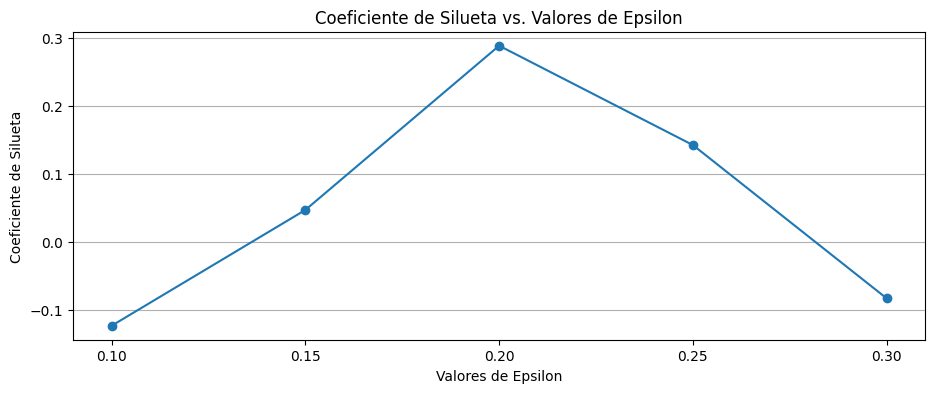

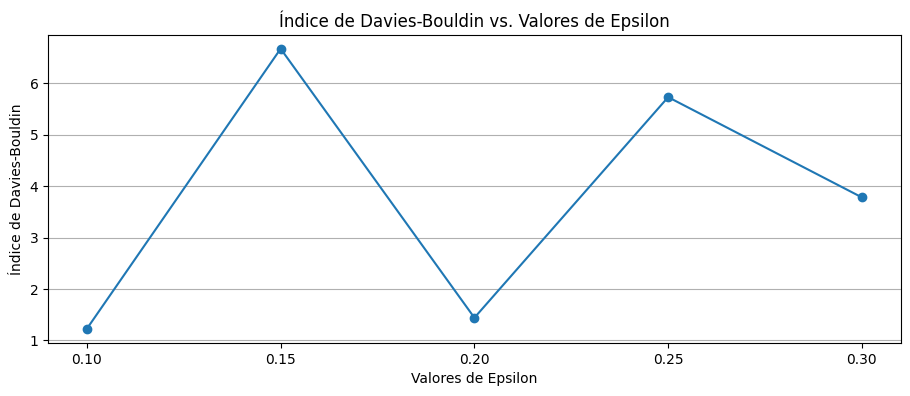

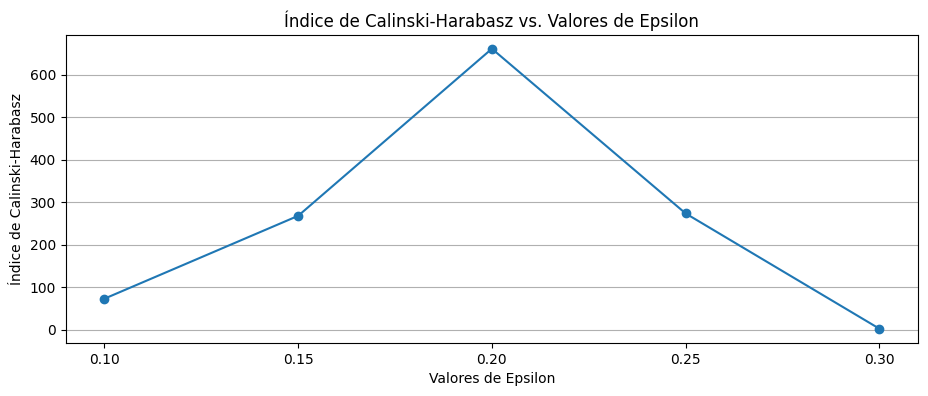

In [36]:
plt.figure(figsize=(11, 4))
plt.plot(epsilons, epsilon_siluetas, marker='o', linestyle='-')
plt.title('Coeficiente de Silueta vs. Valores de Epsilon')
plt.xlabel('Valores de Epsilon')
plt.ylabel('Coeficiente de Silueta')
plt.xticks(epsilons)
plt.grid(True, axis='y')
plt.show()

plt.figure(figsize=(11, 4))
plt.plot(epsilons, epsilon_davies_bouldin_indice, marker='o', linestyle='-')
plt.title('Índice de Davies-Bouldin vs. Valores de Epsilon')
plt.xlabel('Valores de Epsilon')
plt.ylabel('Índice de Davies-Bouldin')
plt.xticks(epsilons)
plt.grid(True, axis='y')
plt.show()

plt.figure(figsize=(11, 4))
plt.plot(epsilons, epsilon_calinski_harabasz, marker='o', linestyle='-')
plt.title('Índice de Calinski-Harabasz vs. Valores de Epsilon')
plt.xlabel('Valores de Epsilon')
plt.ylabel('Índice de Calinski-Harabasz')
plt.xticks(epsilons)
plt.grid(True, axis='y')
plt.show()

### Ahora vamos a evaluar el desempeño en función de cómo varía la cantidad de Minpoints, utilizando el epislon = 0.20 que obtuvimos mas arriba

In [38]:
siluetas = []
davies_bouldin_indice = []
calinski_score = []

points = range(1, 8, 1)

for min_points in points:
    dbscan = DBSCAN(eps=0.20, min_samples=min_points).fit(datos_scaled)
    labels = dbscan.labels_
    datos["Cluster"] = labels
    
    # Métricas
    silueta_dbscan = silhouette_score(datos_scaled, labels) if len(np.unique(labels)) > 1 else None
    db_index = davies_bouldin_score(datos_scaled, labels) if len(np.unique(labels)) > 1 else None
    calinski = calinski_harabasz_score(datos_scaled, labels) if len(np.unique(labels)) > 1 else None

    siluetas.append(silueta_dbscan)
    davies_bouldin_indice.append(db_index)
    calinski_score.append(calinski)

    # Conteo de clusters (excluyendo ruido)
    unique_labels = np.unique(labels)
    n_clusters = len(unique_labels[unique_labels != -1])
    n_noise = list(labels).count(-1)

    print(
        f"min_points={min_points} | "
        f"Clusters: {n_clusters} | "
        f"Ruido: {n_noise} | "
        f"Silueta: {silueta_dbscan} | "
        f"Davies-Bouldin: {db_index} | "
        f"Calinski-Harabasz: {calinski}"
    )

min_points=1 | Clusters: 26 | Ruido: 0 | Silueta: -0.026282516523363747 | Davies-Bouldin: 0.47941040263373813 | Calinski-Harabasz: 216.5214970499381
min_points=2 | Clusters: 10 | Ruido: 16 | Silueta: 0.20958845357643244 | Davies-Bouldin: 2.2979537004339647 | Calinski-Harabasz: 436.8671478472201
min_points=3 | Clusters: 6 | Ruido: 24 | Silueta: 0.28795936748288165 | Davies-Bouldin: 1.4385421878054265 | Calinski-Harabasz: 661.4198470135507
min_points=4 | Clusters: 5 | Ruido: 28 | Silueta: 0.39238245565646646 | Davies-Bouldin: 1.3658166034770016 | Calinski-Harabasz: 767.387819434345
min_points=5 | Clusters: 3 | Ruido: 40 | Silueta: 0.6001239518803317 | Davies-Bouldin: 1.7081006961274576 | Calinski-Harabasz: 1133.105471151091
min_points=6 | Clusters: 3 | Ruido: 54 | Silueta: 0.5869140064425463 | Davies-Bouldin: 1.5509653694137504 | Calinski-Harabasz: 1035.6007574795515
min_points=7 | Clusters: 3 | Ruido: 70 | Silueta: 0.5702560589626853 | Davies-Bouldin: 1.6089970350422702 | Calinski-Harab

### Decidimos quedarnos con min_points = 5 ya que arroja los mejores resultados

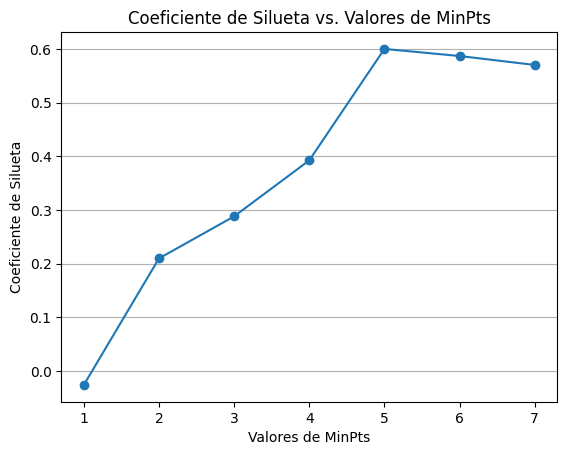

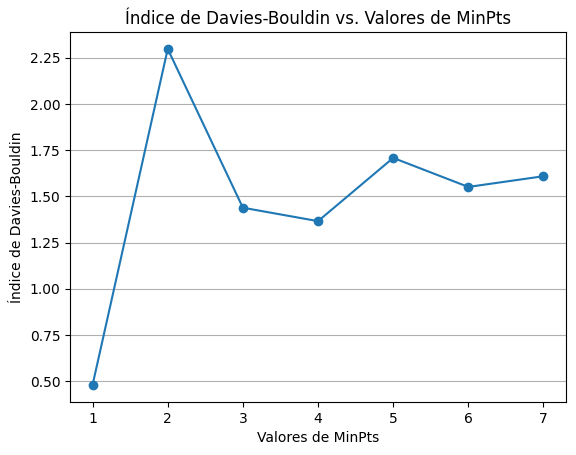

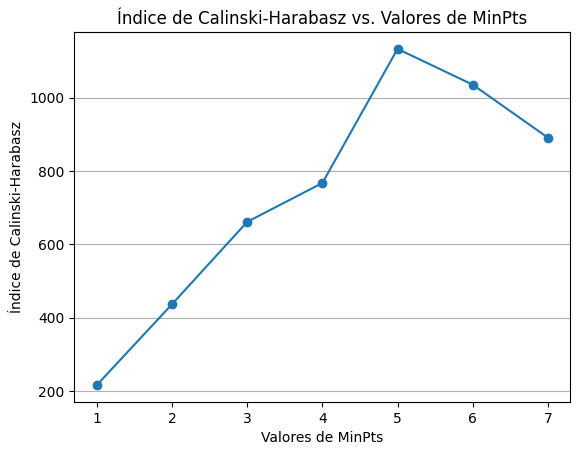

In [39]:
plt.plot(points, siluetas, marker='o', linestyle='-')
plt.title('Coeficiente de Silueta vs. Valores de MinPts')
plt.xlabel('Valores de MinPts')
plt.ylabel('Coeficiente de Silueta')

plt.xticks(points)
plt.grid(True, axis='y')
plt.show()

plt.plot(points, davies_bouldin_indice, marker='o', linestyle='-')
plt.title('Índice de Davies-Bouldin vs. Valores de MinPts')
plt.xlabel('Valores de MinPts')
plt.ylabel('Índice de Davies-Bouldin')

plt.xticks(points)
plt.grid(True, axis='y')
plt.show()

plt.plot(points, calinski_score, marker='o', linestyle='-')
plt.title('Índice de Calinski-Harabasz vs. Valores de MinPts')
plt.xlabel('Valores de MinPts')
plt.ylabel('Índice de Calinski-Harabasz')

plt.xticks(points)
plt.grid(True, axis='y')
plt.show()

# Volvemos a aplicar el algoritmos pero esta vez con los dos parámetros que mejor resultados arrojaban

In [12]:
dbscan = DBSCAN(eps=0.20, min_samples=5).fit(datos_scaled) 

labels = dbscan.labels_ #Extraemos las etiquetas de los clusters

datos_scaled_df["Cluster"] = labels  #Agregamos las etiquetas al DataFrame escalado

silueta_dbscan = silhouette_score(datos_scaled, dbscan.labels_)
db_index = davies_bouldin_score(datos_scaled, dbscan.labels_)
calinski = calinski_harabasz_score(datos_scaled, dbscan.labels_)

print(f'El coeficiente de silueta es: {round(silueta_dbscan,4)}')
print(f'El índice de Davies-Bouldin es: {round(db_index,4)}')
print(f'El índice de Calinski-Harabasz es: {round(calinski,4)}')

unique, counts = np.unique(labels, return_counts=True)
print(list(zip(unique, counts)))

El coeficiente de silueta es: 0.6001
El índice de Davies-Bouldin es: 1.7081
El índice de Calinski-Harabasz es: 1133.1055
[(np.int64(-1), np.int64(40)), (np.int64(0), np.int64(235)), (np.int64(1), np.int64(237)), (np.int64(2), np.int64(238))]


In [13]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)
print("Cantidad de puntos de ruido:", n_noise)
print("Cantidad de clusters encontrados:", n_clusters)

Cantidad de puntos de ruido: 40
Cantidad de clusters encontrados: 3


### A continuación graficamos para poder visualizar los clusters que se han formado

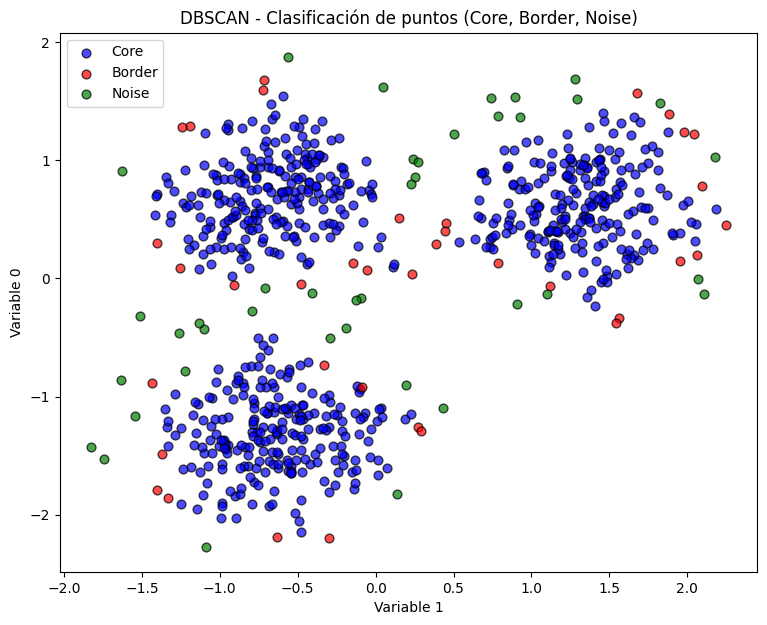

In [14]:
# Los "core points" los guarda DBSCAN internamente:
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[dbscan.core_sample_indices_] = True
# Clasificamos cada punto:
datos['point_type'] = np.where(labels == -1, 'noise',        
                    np.where(core_samples_mask, 'core',   
                             'border'))                   
colors = {'core': 'blue', 'border': 'red', 'noise': 'green'}
plt.figure(figsize=(9,7))
for tipo, color in colors.items():
    subset = datos[datos['point_type'] == tipo]
    plt.scatter(subset['1'], subset['0'],
                c=color, label=tipo.capitalize(), s=40, alpha=0.7, edgecolors='k')
plt.title('DBSCAN - Clasificación de puntos (Core, Border, Noise)')
plt.xlabel('Variable 1')
plt.ylabel('Variable 0')
plt.legend()
plt.show()

### Obtenemos estadísticas sobre los clusters para poder interpretarlos en función de la clasificación de los datos

In [ ]:
datos_scaled_df

In [20]:
datos_scaled_df.groupby("Cluster").agg([ "max","min","mean", "std"])

0                                       1                      \
              max       min      mean       std       max       min      mean   
Cluster                                                                         
-1       1.870438 -2.274474  0.126632  1.097464  2.179037 -1.823801 -0.011414   
 0       1.566778 -0.376722  0.604939  0.355992  2.245794  0.389904  1.319471   
 1      -0.502671 -2.192295 -1.324389  0.335663  0.287882 -1.435145 -0.640449   
 2       1.681418 -0.057139  0.700229  0.342161  0.234517 -1.416202 -0.663163   

                   
              std  
Cluster            
-1       1.138960  
 0       0.357560  
 1       0.358897  
 2       0.344161

A partir de los análisis realizados a cada cluster, podemos decir que los clusters tienen las siguientes características:

CLUSTER 2 (arriba a la izquierda): este cluster en su variable 0 toma valores que van del -0.05 al 1.7, y en la variable 1 toma en su mayoria valores negativos.

CLUSTER 1 (abajo a la izquierda): Es el que más se diferencia de los demás, donde aquellos datos que lo componen son aquellos de valores negativos (en su gran mayoría) en ambas variables.

CLUSTER 0 (el de arriba a la derecha): Este cluster esta compuesto en su mayoría por valores positivos, en la variable 1 su valor mínimo es 0.3 y su máximo 2.2, y en la variable 0 su min es negativo (-0.3) y su max positivo 1.5



### Creamos un mapa de calor para ver qué valores toman las variables en cada cluster


<Axes: ylabel='Cluster'>

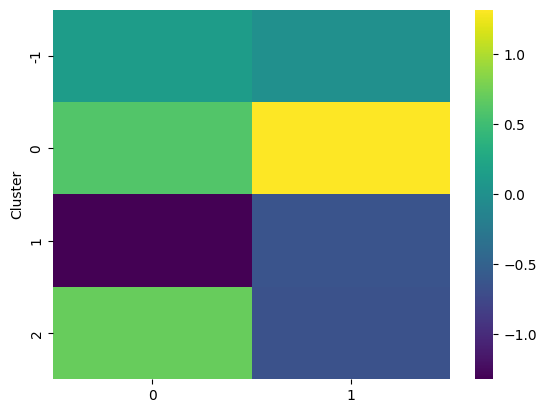

In [19]:
datos_scaled_df.groupby("Cluster").mean().pipe(sns.heatmap, cmap="viridis")